### ReAct Agent Architecture

#### Aim
This is the intuition behind ReAct, a general agent architecture.

1. act - let the model call specific tools
2. observe - pass the tool output back to the model
3. reason - let the model reason about the tool output to decide what to do next (e.g., call another tool or just respond directly)

![image.png](attachment:image.png)

In [1]:
from langchain_community.tools import ArxivQueryRun,WikipediaQueryRun
from langchain_community.utilities import WikipediaAPIWrapper,ArxivAPIWrapper

C:\Users\aadit\AppData\Local\Temp\ipykernel_8792\1871147362.py:1: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.tools import ArxivQueryRun,WikipediaQueryRun


In [2]:
api_wrapper_arxiv = ArxivAPIWrapper(
    top_k_results=2,
    doc_content_chars_max=500
)
arxiv=ArxivQueryRun(api_wrapper=api_wrapper_arxiv)
print(arxiv.name)

arxiv


In [3]:
arxiv.invoke("Attention iss all you need")

AttributeError: 'Search' object has no attribute 'results'

In [3]:
import requests

url = "https://export.arxiv.org/api/query"

response = requests.get(
    url,
    params={
        "search_query": 'all:"Attention is all you need"',
        "max_results": 2
    },
    timeout=30
)

print("Status:", response.status_code)
print(response.text[:1000])

Status: 200
<?xml version='1.0' encoding='UTF-8'?>
<feed xmlns:opensearch="http://a9.com/-/spec/opensearch/1.1/" xmlns:arxiv="http://arxiv.org/schemas/atom" xmlns="http://www.w3.org/2005/Atom">
  <id>https://arxiv.org/api/PGg0+fRm878Q/2RjzufBk7e7iuQ</id>
  <title>arXiv Query: search_query=all:"Attention is all you need"&amp;id_list=&amp;start=0&amp;max_results=2</title>
  <updated>2026-10-26T10:48:15Z</updated>
  <link href="https://arxiv.org/api/query?search_query=all:%22Attention+is+all+you+need%22&amp;start=0&amp;max_results=2&amp;id_list=" type="application/atom+xml"/>
  <opensearch:itemsPerPage>2</opensearch:itemsPerPage>
  <opensearch:totalResults>47</opensearch:totalResults>
  <opensearch:startIndex>0</opensearch:startIndex>
  <entry>
    <id>http://arxiv.org/abs/2604.21816v1</id>
    <title>Tool Attention Is All You Need: Dynamic Tool Gating and Lazy Schema Loading for Eliminating the MCP/Tools Tax in Scalable Agentic Workflows</title>
    <updated>2026-04-23T16:10:00Z</updated

In [4]:
import requests
from langchain_core.tools import tool

@tool
def arxiv_search(query: str) -> str:
    """Search research papers on arXiv and return titles, summaries and URLs."""

    response = requests.get(
        "https://export.arxiv.org/api/query",
        params={
            "search_query": f'all:"{query}"',
            "start": 0,
            "max_results": 2,
            "sortBy": "relevance",
            "sortOrder": "descending",
        },
        timeout=30,
    )
    response.raise_for_status()

    import xml.etree.ElementTree as ET

    root = ET.fromstring(response.text)
    ns = {"atom": "http://www.w3.org/2005/Atom"}

    papers = []

    for entry in root.findall("atom:entry", ns):
        title = entry.findtext("atom:title", default="", namespaces=ns)
        summary = entry.findtext("atom:summary", default="", namespaces=ns)
        link = entry.findtext("atom:id", default="", namespaces=ns)

        papers.append(
            f"Title: {title.strip()}\n"
            f"Summary: {summary.strip()}\n"
            f"URL: {link}"
        )

    return "\n\n".join(papers) if papers else "No papers found."

print(arxiv_search.invoke({"query": "Attention is all you need"}))

Title: Tool Attention Is All You Need: Dynamic Tool Gating and Lazy Schema Loading for Eliminating the MCP/Tools Tax in Scalable Agentic Workflows
Summary: The Model Context Protocol (MCP) has become a common interface for connecting large language model (LLM) agents to external tools, but its reliance on stateless, eager schema injection imposes a hidden per-turn overhead the MCP Tax or Tools Tax that practitioner reports place between roughly 10k and 60k tokens in typical multi-server deployments. This payload inflates the key-value cache, is associated with reasoning degradation as context utilization approaches published fracture points around 70%, and turns token budgets into a recurring operational cost. We introduce Tool Attention, a middleware-layer mechanism that generalizes the "Attention Is All You Need" paradigm from self-attention over tokens to gated attention over tools. Tool Attention combines (i) an Intent Schema Overlap (ISO) score from sentence embeddings, (ii) a sta

In [5]:
api_wrapper_wiki=WikipediaAPIWrapper(top_k_results=1,doc_content_chars_max=500)
wiki=WikipediaQueryRun(api_wrapper=api_wrapper_wiki)
wiki.name

'wikipedia'

In [9]:
import wikipedia

try:
    result = wikipedia.summary(
        "Machine learning",
        sentences=3,
        auto_suggest=False
    )
    print(result)
except Exception as e:
    print(type(e).__name__, e)

Machine learning (ML) is a field of study in artificial intelligence concerned with the development and study of statistical algorithms that can learn from  data and generalize to unseen data, and thus perform tasks without being explicitly programmed.
Statistics and mathematical optimisation methods compose the foundations of machine learning. Data mining is a related field of study, focusing on exploratory data analysis (EDA) through unsupervised learning.


In [10]:
from langchain_community.utilities import WikipediaAPIWrapper
from langchain_community.tools import WikipediaQueryRun

api_wrapper_wiki = WikipediaAPIWrapper(
    top_k_results=1,
    doc_content_chars_max=500
)

wiki = WikipediaQueryRun(api_wrapper=api_wrapper_wiki)

print(wiki.invoke("What is machine learning"))

Page: Machine learning
Summary: Machine learning (ML) is a field of study in artificial intelligence concerned with the development and study of statistical algorithms that can learn from  data and generalize to unseen data, and thus perform tasks without being explicitly programmed.
Statistics and mathematical optimisation methods compose the foundations of machine learning. Data mining is a related field of study, focusing on exploratory data analysis (EDA) through unsupervised learning.
From 


In [13]:
from dotenv import load_dotenv
load_dotenv()

import os

os.environ["TAVILY_API_KEY"]=os.getenv("TAVILY_API_KEY")
os.environ["GROQ_API_KEY"]=os.getenv("GROQ_API_KEY")
os.environ["LANGCHAIN_API_KEY"]=os.getenv("LANGCHAIN_API_KEY")
os.environ["LANGCHAIN_TRACING_V2"] = "true"
os.environ["LANGCHAIN_PROJECT"]= "ReAct-agent"

In [14]:
### Custom Functions
def multiply(a: int, b:int) -> int:
    """Multiply a and b.
    
    Args:
        a: first int
        b: second int
    """
    return a * b

# This will be a tool
def add(a: int, b: int) -> int:
    """Adds a and b.
    
    Args:
        a: first int
        b: second int
    """
    return a + b

def divide(a: int, b: int) -> float:
    """Divide a and b.
    
    Args:
        a: first int
        b: second int
    """
    return a / b

tools = [arxiv, wiki, add, multiply, divide]

In [15]:
### Tavily Search Tool
from langchain_community.tools.tavily_search import TavilySearchResults

tavily = TavilySearchResults()

C:\Users\aadit\AppData\Local\Temp\ipykernel_8792\3584238.py:4: LangChainDeprecationWarning: The class `TavilySearchResults` was deprecated in LangChain 0.3.25 and will be removed in 1.0. An updated version of the class exists in the `langchain-tavily package and should be used instead. To use it run `pip install -U `langchain-tavily` and import as `from `langchain_tavily import TavilySearch``.
  tavily = TavilySearchResults()


In [16]:
tavily.invoke("Provide me the recent AI news for march 3rd 2025")

[{'title': 'March 2025 - The Artificial Intelligence Revolution',
  'url': 'https://choreoadvisors.com/market-perspectives/march-2025-the-artificial-intelligence-revolution',
  'content': 'There are plenty of signs that AI is beginning to have a material effect on the world. One of the early signals may be the valuation of AI-related private companies such as OpenAI. Investors are willing to pay up for what they believe could be a potential leader in the field. The ChatGPT maker’s most recent funding round in the private markets valued the company at $300 billion. At current markets as of 3/3/25, this would place it as the 27th largest company in the S&P 500, a staggering valuation for a private entity. [...] There are risks abounding in the technology itself and the rapidly evolving investment landscape surrounding AI. Often with new technology, the initial spend is high as an arms race of sorts ensues. Also of note, the first companies and technology paths are often not the ultimate 

In [17]:
## Combine all the tools in the list

tools = [arxiv, wiki, tavily, add, divide,multiply]

In [15]:
!uv add langchain groq

Resolved 209 packages in 2.66s
   Building rag @ file:///D:/Mission%20Project/RAG
      Built rag @ file:///D:/Mission%20Project/RAG
Prepared 1 package in 30ms
Uninstalled 19 packages in 900ms
         If the cache and target directories are on different filesystems, hardlinking may not be supported.
         If this is intentional, set `export UV_LINK_MODE=copy` or use `--link-mode=copy` to suppress this warning.
error: Failed to install: orjson-3.12.0-cp313-cp313-win_amd64.whl (orjson==3.12.0)
  cause: Failed to copy to `D:\Mission Project\RAG\.venv\Lib\site-packages\orjson\orjson.cp313-win_amd64.pyd`
  cause: Failed to persist temporary file to D:\Mission Project\RAG\.venv\Lib\site-packages\orjson\orjson.cp313-win_amd64.pyd: failed to persist temporary file: Access is denied. (os error 5)


In [19]:
## Initialize my LLM model

from langchain_groq import ChatGroq

llm = ChatGroq(
    model="openai/gpt-oss-120b",
    temperature=0
)

llm_with_tools = llm.bind_tools(tools)

In [20]:
from pprint import pprint
from langchain_core.messages import AIMessage, HumanMessage
llm_with_tools.invoke([HumanMessage(content=f"What is the recent AI News")])

AIMessage(content='', additional_kwargs={'reasoning_content': 'The user asks: "What is the recent AI News". They likely want a summary of recent AI news. Need up-to-date info. Use search tool (tavily_search_results_json) for recent AI news. Probably need to fetch top results. Then summarize. Let\'s search.', 'tool_calls': [{'id': 'fc_afac1e5d-a766-4009-b40a-180254614736', 'function': {'arguments': '{"query":"latest AI news 2024 October"}', 'name': 'tavily_search_results_json'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 95, 'prompt_tokens': 378, 'total_tokens': 473, 'completion_time': 0.19946786, 'completion_tokens_details': {'reasoning_tokens': 58}, 'prompt_time': 0.018019293, 'prompt_tokens_details': None, 'queue_time': 0.397542241, 'total_time': 0.217487153}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_9241e9962b', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run

In [21]:
llm_with_tools.invoke([HumanMessage(content=f"What is the recent AI News")]).tool_calls

[{'name': 'tavily_search_results_json',
  'args': {'query': 'latest AI news 2024 October'},
  'id': 'fc_25964c01-466e-4bc1-86aa-260abf0f1715',
  'type': 'tool_call'}]

In [22]:
## State Schema
from typing_extensions import TypedDict
from langchain_core.messages import AnyMessage
from typing import Annotated
from langgraph.graph.message import add_messages
class State(TypedDict):
    messages:Annotated[list[AnyMessage],add_messages]

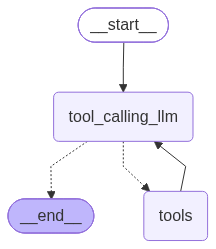

In [24]:
## Entire chatbot with langgraph
from IPython.display import Image, display
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

## NODE defination
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tools.invoke(state["messages"])]}

## Build graph
builder = StateGraph(State)
builder.add_node("tool_calling_llm", tool_calling_llm)
builder.add_node("tools", ToolNode(tools))

builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition,
)

builder.add_edge("tools", "tool_calling_llm")

graph = builder.compile()

# View
display(Image(graph.get_graph().draw_mermaid_png()))

In [25]:
messages=graph.invoke({"messages":HumanMessage(content="Provide me the top 10 recent AI news for March 3rd 2025, add 5 plus 5 and then multiply by 10")})
for m in messages['messages']:
    m.pretty_print()

================================ Human Message =================================

Provide me the top 10 recent AI news for March 3rd 2025, add 5 plus 5 and then multiply by 10
================================== Ai Message ==================================
Tool Calls:
  tavily_search_results_json (fc_7e1ba523-6128-4990-ac39-545d1aef4e7c)
 Call ID: fc_7e1ba523-6128-4990-ac39-545d1aef4e7c
  Args:
    query: AI news March 3 2025 top news
================================= Tool Message =================================
Name: tavily_search_results_json

[{"title": "Top Viral AI & Tech News (March 3 - March 7, 2025)", "url": "https://www.youtube.com/watch?v=n0icz4P221E", "content": "[1:14:52] communicate with him on that. And um Jedi says, \"Do you have a mentorship option?\" Not at this time, but hey, let's connect and we can definitely look\n[1:15:01] into that. So, tap into the link. Would love to do a one-on-one consultation. So I've helped people all over the world to\n[1:15:09] transiti

In [26]:
messages = graph.invoke({"messages":HumanMessage(content="What is maching learning")})
for m in messages['messages']:
    m.pretty_print()

================================ Human Message =================================

What is maching learning
================================== Ai Message ==================================

**Machine learning (ML)** is a sub‑field of artificial intelligence (AI) that focuses on building systems that can **learn from data** and improve their performance on a task without being explicitly programmed for every possible situation.

---

## Core Idea
1. **Data → Model → Prediction**  
   - **Data**: examples (e.g., images, text, sensor readings).  
   - **Model**: a mathematical function (often a set of parameters) that maps inputs to outputs.  
   - **Learning**: an algorithm adjusts the model’s parameters so that its predictions match the observed data as closely as possible.

2. **Generalization**  
   The goal is not just to memorize the training data but to **generalize**—make accurate predictions on new, unseen data.

---

## Main Categories of Machine‑Learning Algorithms

| Category |

### Agent Memory
#### Aim
Lets introduce Agent With Memory

In [27]:
messages=graph.invoke({"messages":HumanMessage(content="What is 5 plus 8")})
for m in messages['messages']:
    m.pretty_print()

================================ Human Message =================================

What is 5 plus 8
================================== Ai Message ==================================

5 + 8 = 13.


In [28]:
messages=[HumanMessage(content="Divide that by 5")]
messages=graph.invoke({"messages":messages})
for m in messages['messages']:
    m.pretty_print()

================================ Human Message =================================

Divide that by 5
================================== Ai Message ==================================

I’m not sure which value you’d like to divide by 5. Could you let me know the number (or expression) you want to have divided?


#### MemorySaver
LangGraph can use a checkpointer to automatically save the graph state after each step.

This built-in persistence layer gives us memory, allowing LangGraph to pick up from the last state update.

One of the easiest checkpointers to use is the MemorySaver, an in-memory key-value store for Graph state.

All we need to do is simply compile the graph with a checkpointer, and our graph has memory!

![image2.png](attachment:image2.png)

In [29]:
from langchain_groq import ChatGroq

llm = ChatGroq(
    model="openai/gpt-oss-120b",
    temperature=0
)

llm_with_tools = llm.bind_tools(tools)

In [30]:
### Entire Chatbot With LangGraph
from IPython.display import Image, display
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

### Node definition
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tools.invoke(state["messages"])]}

# Build graph
builder = StateGraph(State)
builder.add_node("tool_calling_llm", tool_calling_llm)
builder.add_node("tools", ToolNode(tools))

builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition,
)
builder.add_edge("tools","tool_calling_llm")


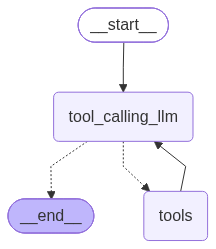

In [31]:
from langgraph.checkpoint.memory import MemorySaver
memory = MemorySaver()
graph_memory = builder.compile(checkpointer=memory)

#View
display(Image(graph_memory.get_graph().draw_mermaid_png()))

In [32]:
## Specify the thread

config = {"configurable":{"thread_id":"1"}}

## Specify an input
messages = [HumanMessage(content="Add 12 and 13.")]
messages = graph_memory.invoke({"messages":messages}, config=config)
for m in messages['messages']:
    m.pretty_print()

================================ Human Message =================================

Add 12 and 13.
================================== Ai Message ==================================
Tool Calls:
  add (fc_25c2bdfd-92bc-4383-909b-793364598bd4)
 Call ID: fc_25c2bdfd-92bc-4383-909b-793364598bd4
  Args:
    a: 12
    b: 13
================================= Tool Message =================================
Name: add

25
================================== Ai Message ==================================

The sum of 12 and 13 is **25**.


In [33]:
messages = [HumanMessage(content="add that number to 25")]
messages = graph_memory.invoke({"messages":messages}, config=config)
for m in messages['messages']:
    m.pretty_print()

================================ Human Message =================================

Add 12 and 13.
================================== Ai Message ==================================
Tool Calls:
  add (fc_25c2bdfd-92bc-4383-909b-793364598bd4)
 Call ID: fc_25c2bdfd-92bc-4383-909b-793364598bd4
  Args:
    a: 12
    b: 13
================================= Tool Message =================================
Name: add

25
================================== Ai Message ==================================

The sum of 12 and 13 is **25**.
================================ Human Message =================================

add that number to 25
================================== Ai Message ==================================

Adding 25 to the previous result (25) gives **50**.


In [35]:
messages = [HumanMessage(content="then multiplty that number by 2")]
messages=graph_memory.invoke({"messages":messages},config=config)
for m in messages['messages']:
    m.pretty_print()

================================ Human Message =================================

Add 12 and 13.
================================== Ai Message ==================================
Tool Calls:
  add (fc_25c2bdfd-92bc-4383-909b-793364598bd4)
 Call ID: fc_25c2bdfd-92bc-4383-909b-793364598bd4
  Args:
    a: 12
    b: 13
================================= Tool Message =================================
Name: add

25
================================== Ai Message ==================================

The sum of 12 and 13 is **25**.
================================ Human Message =================================

add that number to 25
================================== Ai Message ==================================

Adding 25 to the previous result (25) gives **50**.
================================ Human Message =================================

then multiplty that number by 2
================================== Ai Message ==================================

Multiplying 50 by 2 yields **100**.
